# Final Analysis Notebook (Code-Output Appendix)

AAI-500 Final Team Project, Team 10. UCI Default of Credit Card Clients (30,000 customers, 23 features, one yes/no target: did the customer miss the next month's payment).

This notebook runs the team's scripts from `src/` and shows their output. It does not copy their logic. Nothing here writes to `data/` or `reports/`. Every number printed below comes from running the code at the time the notebook was executed.

Sections: 1 Setup, 2 Load raw data, 3 Cleaning, 4 Exploratory analysis, 5 Modeling, 6 Neural network, 7 Conclusions.

Run from the repo root or from `notebooks/`. The modeling step takes about a minute. The neural network section reuses saved results and refits one network (a few seconds); the full 3-minute search is not repeated here (see section 6).

**AI-tool disclosure.** Siddhant Bhura used Claude Code (Anthropic) to help write and revise this notebook and the scripts `neural_network.py`, `robustness_checks.py` and `data_cleaning.py`. The code was run and its output checked. See the README and report Section 1. Teammates add their own line for their files.

## 1. Setup

In [1]:
import contextlib
import io
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

# Find the repo root whether we start in the root or in notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src" / "data_cleaning.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import data_cleaning as dc
import modeling as mdl
import neural_network as nn

FIG = ROOT / "reports" / "figures"
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

import sklearn
print("Repo root:", ROOT.name)
print("Python", sys.version.split()[0], "| pandas", pd.__version__,
      "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

Repo root: final-project
Python 3.14.6 | pandas 3.0.6 | numpy 2.5.3 | scikit-learn 1.9.1


## 2. Load raw data

In [2]:
raw, coerced = dc.load_raw_data()
print("Raw shape (rows, columns):", raw.shape)
print("Non-numeric values coerced to missing:", coerced)
raw.head()

Raw shape (rows, columns): (30000, 25)
Non-numeric values coerced to missing: {}


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 3. Data cleaning

This calls `clean_dataframe()` from `src/data_cleaning.py`. It checks missing values and duplicates, preserves financial outliers (no winsorization; tails are counted for the log only), folds undocumented education and marriage codes into "others", and renames `PAY_0` to `PAY_1`. The cleaning script itself writes the cleaned CSV; this notebook does not.

In [3]:
report = dc.clean_dataframe()
print(dc.generate_cleaning_report(report))

DATA CLEANING SUMMARY

Original shape: (30000, 25)
Final shape:    (30000, 25)

--- Non-numeric values coerced to missing (by column) ---
  None -- every value in the raw file was already numeric.

--- Missing values (before cleaning) ---
ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                 

In [4]:
cleaned = report["df_cleaned"]
saved = pd.read_csv(dc.OUTPUT_PATH)
print("Cleaned shape in memory:", cleaned.shape)
print("Saved CSV shape:        ", saved.shape)
same = np.allclose(
    cleaned.select_dtypes("number").to_numpy(dtype=float),
    saved[cleaned.select_dtypes("number").columns].to_numpy(dtype=float),
)
print("Saved CSV matches the in-memory cleaned data:", same)

Cleaned shape in memory: (30000, 25)
Saved CSV shape:         (30000, 25)
Saved CSV matches the in-memory cleaned data: True


## 4. Exploratory analysis (key outputs)

The full EDA lives in `src/exploratory_analysis.py` and `reports/eda_findings.md`. Below are the headline tables, computed directly from the cleaned data, followed by the saved EDA figures.

In [5]:
target = mdl.TARGET
rate = cleaned[target].mean()
print(f"Default rate: {rate:.2%} ({int(cleaned[target].sum()):,} of {len(cleaned):,})")
print(f"Non-default to default ratio: {(1 - rate) / rate:.2f} to 1")

Default rate: 22.12% (6,636 of 30,000)
Non-default to default ratio: 3.52 to 1


In [6]:
# Default rate by most recent repayment status (PAY_1).
by_pay = cleaned.groupby("PAY_1")[target].agg(customers="size", default_rate="mean")
by_pay["default_rate"] = by_pay["default_rate"].round(4)
by_pay

,customers,default_rate
PAY_1,,
-2,2759,0.1323
-1,5686,0.1678
0,14737,0.1281
1,3688,0.3395
2,2667,0.6914
3,322,0.7578
4,76,0.6842
5,26,0.5000
6,11,0.5455


In [7]:
# Default rate by credit-limit quintile and by education code.
limit_q = pd.qcut(cleaned["LIMIT_BAL"], 5, duplicates="drop")
print(cleaned.groupby(limit_q, observed=True)[target].agg(customers="size", default_rate="mean").round(4))
print()
print(cleaned.groupby("EDUCATION")[target].agg(customers="size", default_rate="mean").round(4))

                      customers  default_rate
LIMIT_BAL                                    
(9999.999, 50000.0]        7676        0.3179
(50000.0, 100000.0]        4822        0.2580
(100000.0, 180000.0]       6123        0.1986
(180000.0, 270000.0]       5421        0.1686
(270000.0, 525000.0]       5958        0.1380

           customers  default_rate
EDUCATION                         
1              10585        0.1923
2              14030        0.2373
3               4917        0.2516
4                468        0.0705


Class balance


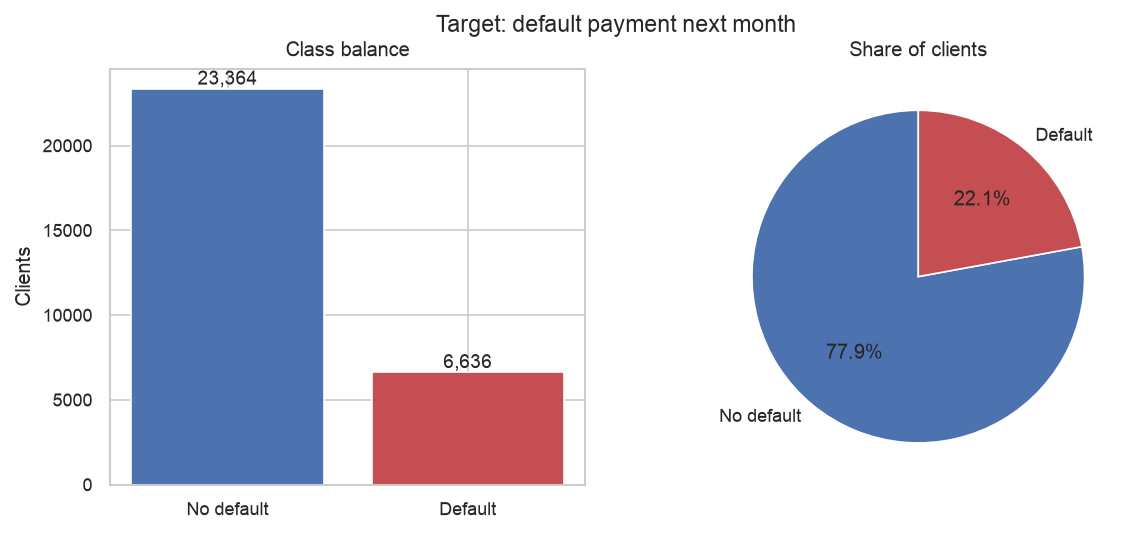

Repayment history versus default


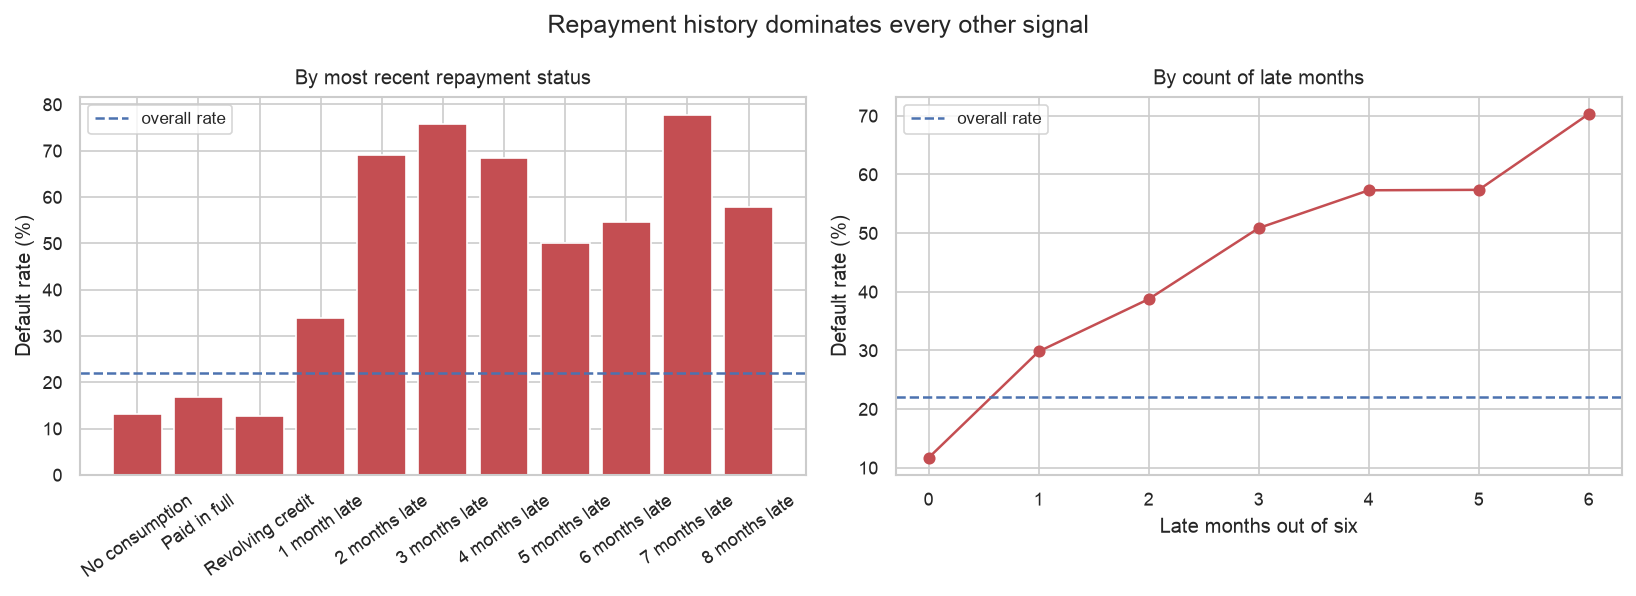

Predictive power of each feature


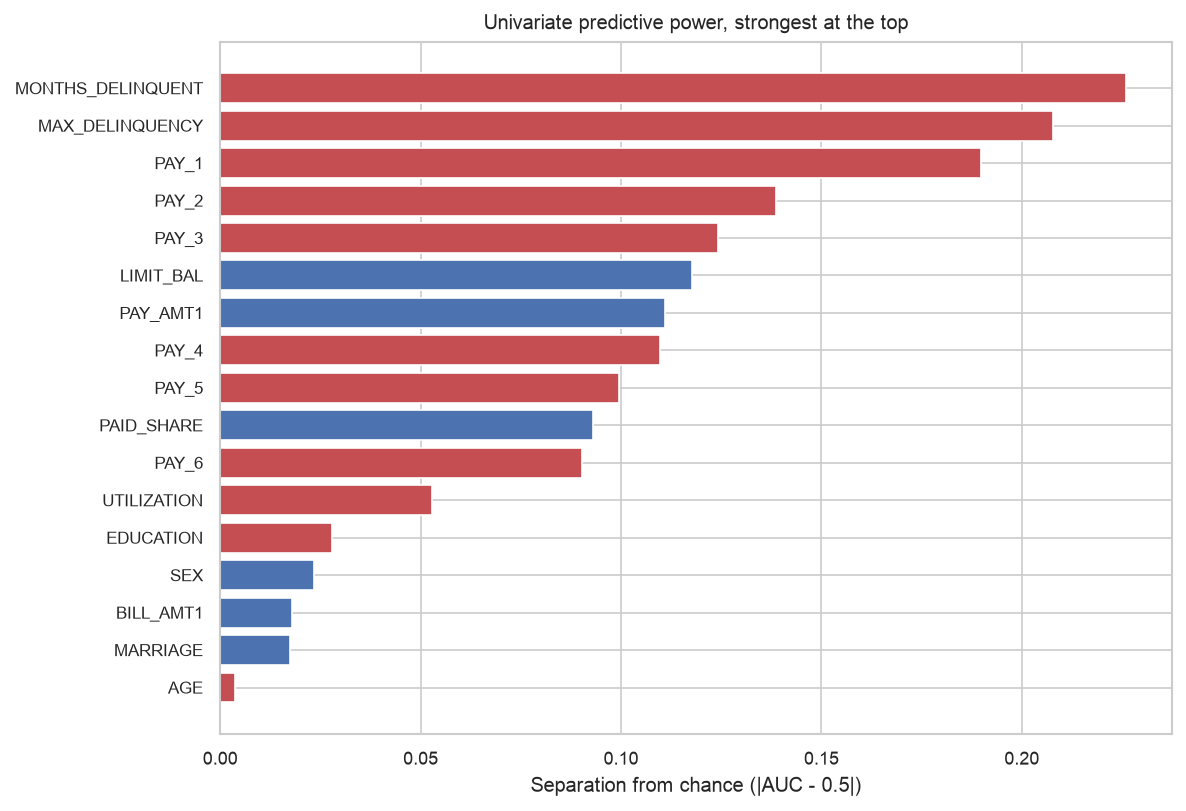

Cleaning validation


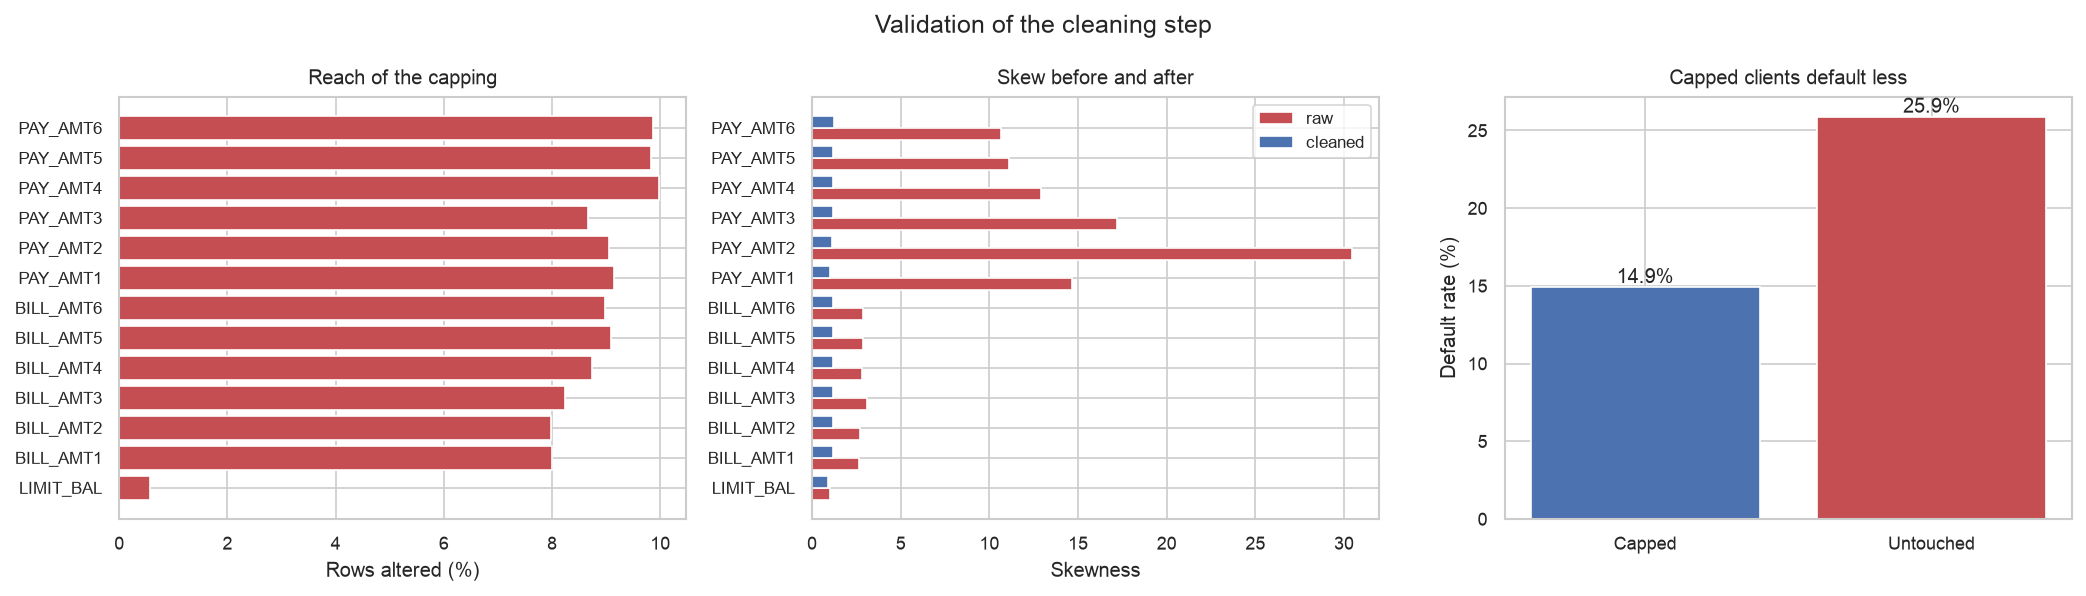

In [8]:
for name, caption in [
    ("01_class_balance.png", "Class balance"),
    ("04_repayment_history.png", "Repayment history versus default"),
    ("10_predictive_power.png", "Predictive power of each feature"),
    ("12_cleaning_validation.png", "Cleaning validation"),
]:
    print(caption)
    display(Image(filename=str(FIG / name), width=800))

## 5. Modeling summary

This imports `src/modeling.py` and calls its own `engineer_features()` and `run_comparison()`. Each combination of feature set and model is scored with 5-fold cross-validation on the training split (80 percent of rows). The metric used for ranking is PR-AUC, which suits an imbalanced target. The 20 percent hold-out test set is used only for the final report of each row. The script's text log is captured and not printed, and no files are written.

In [9]:
df_model = mdl.engineer_features(mdl.load_cleaned_data())
with contextlib.redirect_stdout(io.StringIO()):
    leaderboard, artifacts = mdl.run_comparison(df_model)
mdl._findings.clear()  # drop the captured log lines, nothing is saved

print("Models compared:", len(leaderboard))
leaderboard.columns.tolist()

Models compared: 9


['feature_set',
 'model',
 'threshold',
 'cv_roc_auc_mean',
 'cv_roc_auc_std',
 'cv_average_precision_mean',
 'cv_average_precision_std',
 'cv_f1_mean',
 'cv_f1_std',
 'cv_recall_mean',
 'cv_recall_std',
 'cv_precision_mean',
 'cv_precision_std',
 'test_roc_auc',
 'test_pr_auc',
 'test_precision',
 'test_recall',
 'test_f1']

In [10]:
cols = ["feature_set", "model", "cv_average_precision_mean", "cv_average_precision_std",
        "test_pr_auc", "test_roc_auc", "threshold", "test_precision", "test_recall", "test_f1"]
leaderboard[cols].round(4).reset_index(drop=True)

,feature_set,model,cv_average_precision_mean,cv_average_precision_std,test_pr_auc,test_roc_auc,threshold,test_precision,test_recall,test_f1
0,kitchen_sink,hist_gradient_boosting,0.5600,0.0060,0.5499,0.7760,0.571,0.5230,0.5561,0.5391
1,kitchen_sink,random_forest,0.5585,0.0073,0.5558,0.7750,0.437,0.4423,0.6436,0.5242
2,extended,random_forest,0.5547,0.0082,0.5548,0.7718,0.481,0.4552,0.6089,0.5210
3,extended,hist_gradient_boosting,0.5542,0.0077,0.5538,0.7712,0.511,0.4765,0.5885,0.5266
4,baseline_eda,hist_gradient_boosting,0.5406,0.0089,0.5354,0.7537,0.542,0.5058,0.5584,0.5308
5,baseline_eda,random_forest,0.5394,0.0105,0.5415,0.7531,0.519,0.4901,0.5787,0.5308
6,baseline_eda,logistic_regression,0.5101,0.0121,0.5081,0.7311,0.565,0.5196,0.5283,0.5239
7,kitchen_sink,logistic_regression,0.5094,0.0143,0.4994,0.7489,0.542,0.4766,0.5592,0.5146
8,extended,logistic_regression,0.5090,0.0138,0.4980,0.7447,0.565,0.4876,0.5479,0.5160


In [11]:
top = leaderboard.sort_values("cv_average_precision_mean", ascending=False).head(10)
labels = top["feature_set"] + " / " + top["model"]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(labels[::-1], top["cv_average_precision_mean"][::-1],
        xerr=top["cv_average_precision_std"][::-1], color="#4c78a8", capsize=3)
base = leaderboard.loc[leaderboard["feature_set"] == "baseline_eda"]["cv_average_precision_mean"].max()
ax.axvline(base, color="grey", linestyle="--", label="best baseline_eda")
ax.set_xlim(top["cv_average_precision_mean"].min() - 0.03, top["cv_average_precision_mean"].max() + 0.02)
ax.set_xlabel("Cross-validated PR-AUC (bars show one standard deviation)")
ax.set_title("Top 10 model and feature-set combinations")
ax.legend()
plt.tight_layout()
display(fig)
plt.close(fig)

<Figure size 1200x675 with 1 Axes>

In [12]:
best = leaderboard.iloc[0]
test_default_rate = float(df_model[target].mean())
print(f"Top row in this run: {best['model']} on {best['feature_set']}")
print(f"  CV PR-AUC   {best['cv_average_precision_mean']:.4f} +/- {best['cv_average_precision_std']:.4f}")
print(f"  Test PR-AUC {best['test_pr_auc']:.4f}  (a model with no skill scores about {test_default_rate:.3f})")
print(f"  Test recall {best['test_recall']:.4f}, precision {best['test_precision']:.4f}, threshold {best['threshold']:.3f}")

gap = leaderboard["cv_average_precision_mean"].iloc[0] - leaderboard["cv_average_precision_mean"].iloc[1]
print(f"\nGap between first and second place in CV PR-AUC: {gap:.4f}")
print(f"Typical fold-to-fold standard deviation of the top row: {best['cv_average_precision_std']:.4f}")

Top row in this run: hist_gradient_boosting on kitchen_sink
  CV PR-AUC   0.5600 +/- 0.0060
  Test PR-AUC 0.5499  (a model with no skill scores about 0.221)
  Test recall 0.5561, precision 0.5230, threshold 0.571

Gap between first and second place in CV PR-AUC: 0.0015
Typical fold-to-fold standard deviation of the top row: 0.0060


## 6. Neural network (added to Model Selection and Analysis)

This uses `src/neural_network.py`, which imports the data, features, split and 5-fold CV from `src/modeling.py`, so the comparison is like for like. The network is scikit-learn's `MLPClassifier`. PyTorch and Keras are not installed and not needed for a table of this size.

The full search (24 settings per feature set, 5-fold CV each, about 3 minutes) is expensive, so this notebook reads the saved results from `reports/neural_network/` (produced by `python src/neural_network.py`, byte-identical across repeated runs) and then refits only the winning network to confirm the saved test score. To rerun the whole search here, set `RERUN_FULL_SEARCH = True`.

In [13]:
RERUN_FULL_SEARCH = False   # True re-runs the whole search (about 3 minutes)

NN_DIR = ROOT / "reports" / "neural_network"
if RERUN_FULL_SEARCH:
    import shutil, tempfile
    # Write into a scratch folder so the saved results are not overwritten.
    nn.OUT_DIR = Path(tempfile.mkdtemp(prefix="nn_nb_"))
    with contextlib.redirect_stdout(io.StringIO()):
        nn.main()
    NN_DIR = nn.OUT_DIR
    print("Full search re-run; results in", NN_DIR)

comparison = pd.read_csv(NN_DIR / "model_comparison.csv")
search = pd.read_csv(NN_DIR / "nn_search_results.csv")
print("Search settings tried:", len(search), "(24 per feature set, plus one oversampled variant each)")
cols = ["feature_set", "model", "cv_pr_auc", "cv_pr_auc_std", "cv_roc_auc",
        "test_pr_auc", "test_roc_auc", "test_f1", "test_recall", "test_precision"]
comparison.sort_values("cv_pr_auc", ascending=False)[cols].round(4).reset_index(drop=True)

Search settings tried: 75 (24 per feature set, plus one oversampled variant each)


,feature_set,model,cv_pr_auc,cv_pr_auc_std,cv_roc_auc,test_pr_auc,test_roc_auc,test_f1,test_recall,test_precision
0,kitchen_sink,hist_gradient_boosting,0.5600,0.0060,0.7811,0.5499,0.7760,0.5402,0.5546,0.5265
1,kitchen_sink,random_forest,0.5585,0.0073,0.7844,0.5558,0.7750,0.5415,0.5780,0.5093
2,extended,random_forest,0.5547,0.0082,0.7813,0.5548,0.7718,0.5338,0.5629,0.5075
3,extended,hist_gradient_boosting,0.5542,0.0077,0.7789,0.5538,0.7712,0.5382,0.5652,0.5137
4,extended,mlp_neural_network,0.5520,0.0077,0.7787,0.5527,0.7692,0.5419,0.5365,0.5473
5,baseline_eda,mlp_neural_network,0.5441,0.0078,0.7596,0.5379,0.7479,0.5308,0.5772,0.4913
6,kitchen_sink,mlp_neural_network,0.5438,0.0099,0.7794,0.5397,0.7692,0.5307,0.5237,0.5379
7,baseline_eda,hist_gradient_boosting,0.5406,0.0089,0.7579,0.5354,0.7537,0.5288,0.5396,0.5185
8,baseline_eda,random_forest,0.5394,0.0105,0.7579,0.5415,0.7531,0.5310,0.5396,0.5226
9,baseline_eda,logistic_regression,0.5101,0.0121,0.7443,0.5081,0.7311,0.5224,0.5320,0.5131


Rows are every model on every feature set. Precision, recall and F1 here use a cutoff picked from out-of-fold predictions on the training rows, for all models, so they can differ slightly from the in-sample cutoff `modeling.py` uses. PR-AUC and ROC-AUC do not depend on the cutoff.

In [14]:
nn_rows = comparison[comparison["model"] == "mlp_neural_network"]
best_nn = nn_rows.sort_values("cv_pr_auc", ascending=False).iloc[0]
others = comparison[comparison["model"] != "mlp_neural_network"]
best_other = others.sort_values("cv_pr_auc", ascending=False).iloc[0]
print("Best network :", best_nn["feature_set"], "|", best_nn["config"])
print(f"  CV PR-AUC {best_nn['cv_pr_auc']:.4f} +/- {best_nn['cv_pr_auc_std']:.4f}, test PR-AUC {best_nn['test_pr_auc']:.4f}")
print("Best non-network by CV:", best_other["model"], "on", best_other["feature_set"])
print(f"  CV PR-AUC {best_other['cv_pr_auc']:.4f} +/- {best_other['cv_pr_auc_std']:.4f}, test PR-AUC {best_other['test_pr_auc']:.4f}")
print(f"\nCV gap (network minus best other): {best_nn['cv_pr_auc'] - best_other['cv_pr_auc']:+.4f}")
print(f"Test gap (network minus best other): {best_nn['test_pr_auc'] - best_other['test_pr_auc']:+.4f}")
print(f"Fold-to-fold std is about {best_other['cv_pr_auc_std']:.3f}, so the network and the trees are statistically tied.")

Best network : extended | hidden=(128, 64), alpha=0.1, early_stopping=True
  CV PR-AUC 0.5520 +/- 0.0077, test PR-AUC 0.5527
Best non-network by CV: hist_gradient_boosting on kitchen_sink
  CV PR-AUC 0.5600 +/- 0.0060, test PR-AUC 0.5499

CV gap (network minus best other): -0.0080
Test gap (network minus best other): +0.0028
Fold-to-fold std is about 0.006, so the network and the trees are statistically tied.


Check by refitting: fit the winning network (extended features, hidden layers (128, 64), alpha 0.1, early stopping on) on the training rows and score the test rows. The test PR-AUC should equal the saved value.

In [15]:
X_train, X_test, y_train, y_test = nn.split_data()
fs = mdl.FEATURE_SETS[best_nn["feature_set"]]
num, cat = fs["numeric"], fs["categorical"]
pipe = nn.make_nn_pipeline(nn.make_mlp((128, 64), 0.1, True), num, cat)
res = nn.holdout_at_threshold(pipe, X_train[num + cat], y_train,
                              X_test[num + cat], y_test, best_nn["oof_threshold"])
print(f"Refit test PR-AUC {res['pr_auc']:.4f} vs saved {best_nn['test_pr_auc']:.4f}")
assert abs(res["pr_auc"] - best_nn["test_pr_auc"]) < 5e-4, "refit does not match saved result"
print("Refit matches the saved result.")

Refit test PR-AUC 0.5527 vs saved 0.5527
Refit matches the saved result.


Training loss of the best network


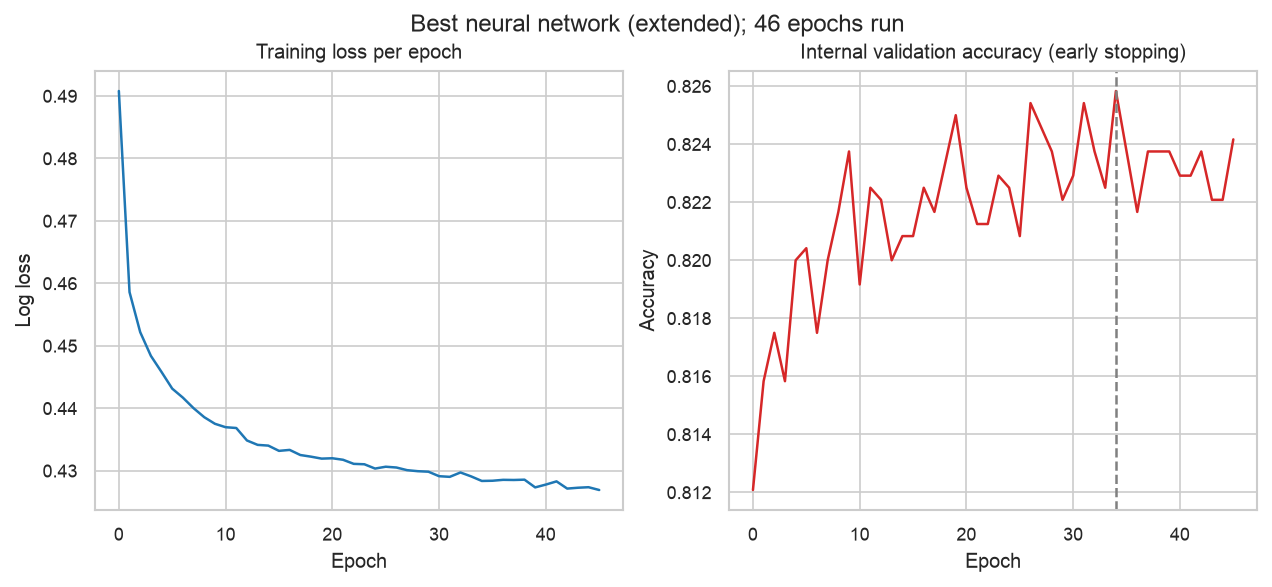

Network vs best non-network model on the test set


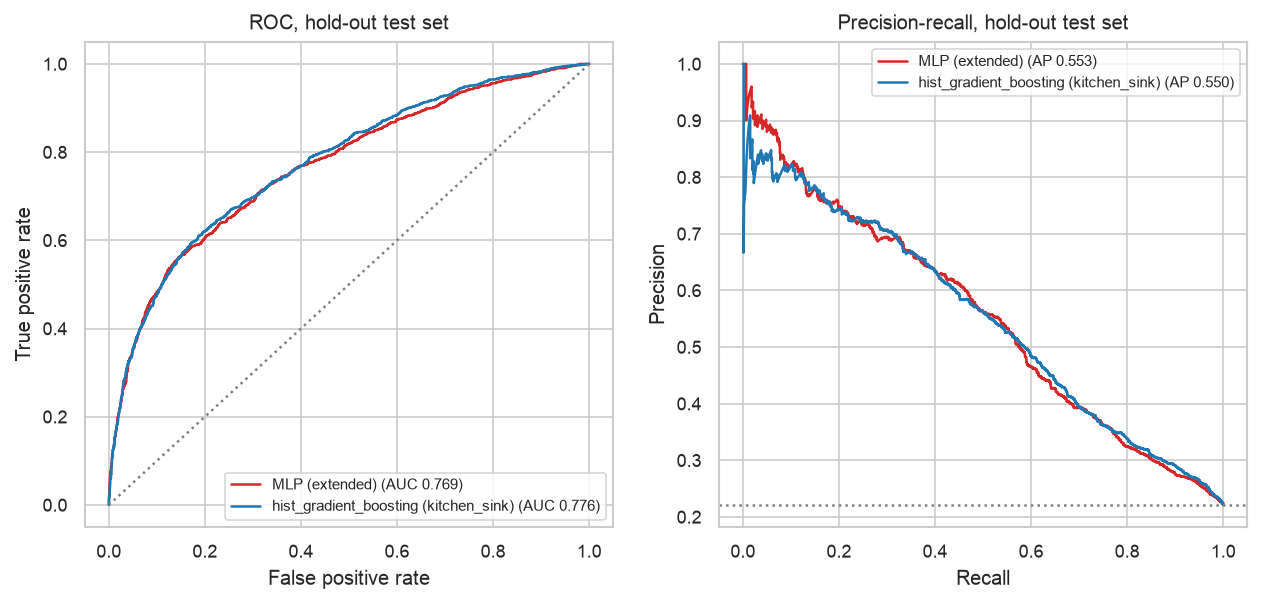

Test confusion matrix of the best network


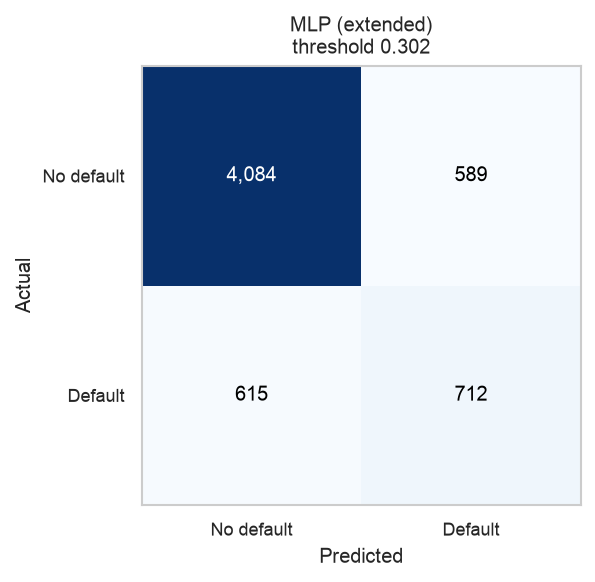

In [16]:
for name, caption in [
    ("fig_nn_loss_curve.png", "Training loss of the best network"),
    ("fig_nn_vs_best_tree_curves.png", "Network vs best non-network model on the test set"),
    ("fig_nn_confusion_matrix.png", "Test confusion matrix of the best network"),
]:
    print(caption)
    display(Image(filename=str(NN_DIR / name), width=700))

Reading of the result: the network ties the tree models on this table and does not beat them. It beats logistic regression on every feature set. Plausible reasons (not proven): the data is a small table dominated by a few stepped repayment-status columns that trees split directly, and the label is noisy so every model lands in a narrow band. Full write-up: `reports/neural_network/neural_network_results.md`.

## 7. Conclusions

- Past repayment behaviour carries most of the signal. The default rate is low for customers who are current or have no balance, and jumps once the latest payment is one or more months late (section 4 table).
- The cleaning step changed the data in the ways listed in the section 3 summary, and the saved CSV matches the in-memory result.
- Every model scores well above a no-skill model. For the two tree-based models, the engineered feature sets score slightly above the baseline feature set. Logistic regression does not gain from them. Compare the CV columns in section 5.
- The top few models are close. The gap between first and second place (printed in section 5) is smaller than the fold-to-fold spread, so which one ranks first is not a strong finding. Treat the choice among the leaders as a judgment call.
- The cleaned and modeled data comes from one country and one six-month window (Taiwan, 2005). The results should not be assumed to hold elsewhere.
- A neural network (section 6) scores about the same as the tree models, with a CV gap smaller than the fold-to-fold spread. It beats logistic regression. It is not clearly better than the trees and is harder to interpret.
- Known limitations of the pipeline: financial outliers are preserved in cleaning (no winsorization), the decision threshold is tuned on the training rows, and results can shift slightly across library versions. The library versions used for this run are printed in section 1.

The written discussion of these points is in `reports/model_findings.md` and the final report. If a figure there differs from a figure here, the report should be regenerated from a single run.